# Matplotlib 学习笔记（入门速通）

> 目标：理解 Figure/Axes 对象模型，掌握 pyplot 与面向对象两种接口、基础图表、样式定制、布局管理与保存输出。

Matplotlib 是 Python 最基础也最强大的绘图库，NumPy、Pandas、SciPy 的绘图功能底层几乎都依赖它。它的学习曲线主要来自一个概念：**图形（Figure）与坐标轴（Axes）的层级关系**。理解了这个，就理解了 Matplotlib 的设计哲学。

**环境准备**
```bash
pip install matplotlib
```

In [5]:
import matplotlib
    
import matplotlib.pyplot as plt
import numpy as np
print("Matplotlib version:", matplotlib.__version__)
#中文和负号显示支持
plt.rcParams['font.sans-serif']=['SimHei'] #用来正常显示中文标签
plt.rcParams['axes.unicode_minus']=False #用来正常显示负号

Matplotlib version: 3.10.5


## 1. 两种接口：pyplot 与面向对象

Matplotlib 提供两套使用风格，理解它们的区别是写好绘图代码的第一步。

| 接口 | 风格 | 特点 | 推荐场景 |
|---|---|---|---|
| **pyplot** | 隐式、命令式 | 自动管理当前 Figure/Axes，代码短 | 快速探索、交互式环境、简单脚本 |
| **面向对象（OO）** | 显式、对象式 | 手动引用 `fig` 和 `ax`，控制精细 | 复杂图表、可复用函数、项目代码 |

**官方建议**：复杂图表和要复用的代码优先用 OO 风格；pyplot 风格适合快速交互工作[citation:1][citation:11]。

**核心对象关系**
```
Figure（整个画布）
  └── Axes（一个坐标系/子图，可多个）
        ├── XAxis / YAxis（坐标轴）
        ├── Line2D / Patch（绘制的图形元素）
        └── Text / Legend / Title（文本元素）
```
一个 Figure 可以包含多个 Axes，但**绘图操作几乎都在 Axes 上进行**。

**函数映射**：pyplot 的 `plt.xlabel()` 对应 OO 的 `ax.set_xlabel()`；`plt.title()` 对应 `ax.set_title()`[citation:14]。

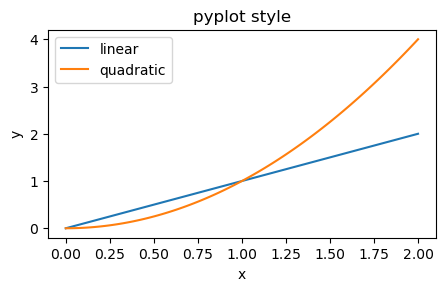

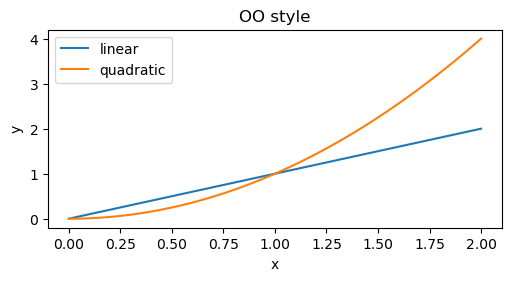

In [2]:
x = np.linspace(0, 2, 100)

# 风格一：pyplot（隐式）
plt.figure(figsize=(5, 2.7))
plt.plot(x, x, label='linear')
plt.plot(x, x**2, label='quadratic')
plt.xlabel('x')
plt.ylabel('y')
plt.title('pyplot style')
plt.legend()
plt.show()

# 风格二：面向对象（显式，推荐）
fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
ax.plot(x, x, label='linear')
ax.plot(x, x**2, label='quadratic')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('OO style')
ax.legend()
plt.show()

## 2. 基础图表类型

Matplotlib 覆盖了绝大多数常用统计图表[citation:3]。

| 函数 | 图表类型 | 适用场景 |
|---|---|---|
| `plot(x, y)` | 折线图 | 趋势、时间序列 |
| `scatter(x, y)` | 散点图 | 变量关系、分布 |
| `bar(x, height)` / `barh()` | 柱状图 / 条形图 | 类别比较 |
| `hist(data, bins)` | 直方图 | 数据分布 |
| `boxplot(data)` | 箱线图 | 分布概括、异常值 |
| `imshow(Z)` | 热力图/图像 | 矩阵、二维网格数据 |
| `pie(sizes)` | 饼图 | 占比构成 |

**OO 风格下的调用**：`ax.plot()`、`ax.scatter()`、`ax.bar()` 等，方法与 pyplot 同名，但作用于指定 Axes。

**`plot` 的灵活性**：`plot(y)` 只用 y 时，x 默认为索引 `0..N-1`；`plot(x, y, 'ro')` 一次指定数据与样式[citation:4]。

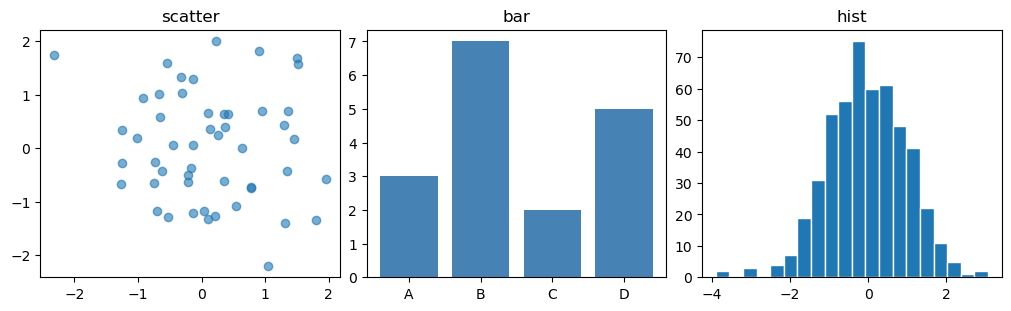

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout='constrained')
rng = np.random.default_rng(0)

# 散点图
axes[0].scatter(rng.normal(size=50), rng.normal(size=50), alpha=0.6)
axes[0].set_title('scatter')

# 柱状图
axes[1].bar(['A', 'B', 'C', 'D'], [3, 7, 2, 5], color='steelblue')
axes[1].set_title('bar')

# 直方图
axes[2].hist(rng.normal(size=500), bins=20, edgecolor='white')
axes[2].set_title('hist')

plt.show()

## 3. 样式与格式字符串

`plot` 的第三个参数 `fmt` 是一个快捷格式字符串，用最少的字符同时指定颜色、标记和线型[citation:4][citation:13]。

**格式字符串语法**：`'[color][marker][linestyle]'`

| 组成部分 | 常用代码 | 含义 |
|---|---|---|
| 颜色 | `'r'` 红、`'g'` 绿、`'b'` 蓝、`'k'` 黑 | 单字母缩写 |
| 标记 | `'o'` 圆、`'s'` 方块、`'^'` 三角、`'+'` 加号 | 数据点标记 |
| 线型 | `'-'` 实线、`'--'` 虚线、`':'` 点线、`'-.'` 点划线 | 连接线样式 |

**示例**：`'ro--'` = 红色圆点 + 虚线；`'g^'` = 绿色三角标记（无线）。

**关键字参数覆盖**：`plot(x, y, 'ro--', linewidth=2, markersize=8)` 中，`fmt` 与关键字参数冲突时，**关键字参数优先**[citation:4]。

**其他常用样式参数**：`color`、`linewidth`、`linestyle`、`marker`、`markersize`、`alpha`（透明度）。

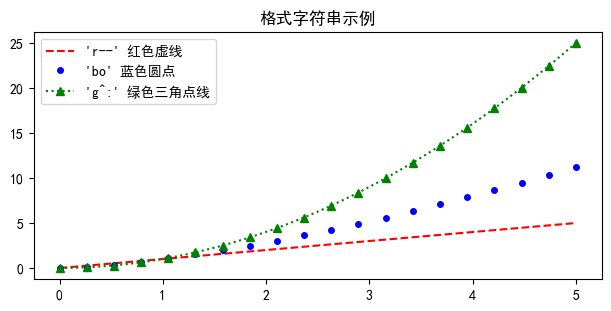

In [6]:
x = np.linspace(0, 5, 20)
fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')

ax.plot(x, x, 'r--', label="'r--' 红色虚线")
ax.plot(x, x**1.5, 'bo', label="'bo' 蓝色圆点", markersize=4)
ax.plot(x, x**2, 'g^:', linewidth=1.5, label="'g^:' 绿色三角点线")
ax.legend()
ax.set_title('格式字符串示例')
plt.show()

## 4. 标签、标题与图例

**OO 风格的核心方法**（pyplot 风格对应去掉 `set_` 前缀）

| OO 方法 | pyplot 等价 | 作用 |
|---|---|---|
| `ax.set_xlabel()` | `plt.xlabel()` | X 轴标签 |
| `ax.set_ylabel()` | `plt.ylabel()` | Y 轴标签 |
| `ax.set_title()` | `plt.title()` | 子图标题 |
| `fig.suptitle()` | `plt.suptitle()` | 整图总标题 |
| `ax.legend()` | `plt.legend()` | 显示图例 |
| `ax.set_xlim()` / `set_ylim()` | `plt.xlim()` / `ylim()` | 坐标范围 |
| `ax.text(x, y, s)` | `plt.text()` | 任意位置添加文本 |

**图例的前提**：绘图时给每条线加 `label` 参数，`legend()` 才会识别。如果没加 `label`，图例为空。

**`legend` 的常用参数**：`loc`（位置，如 `'upper left'`）、`fontsize`、`frameon`（是否显示边框）。

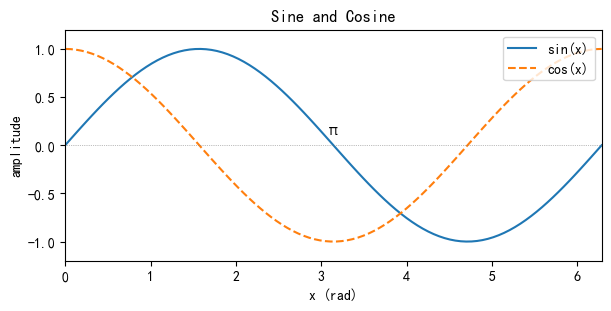

In [7]:
x = np.linspace(0, 2*np.pi, 100)
fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')

ax.plot(x, np.sin(x), label='sin(x)', color='C0')
ax.plot(x, np.cos(x), label='cos(x)', color='C1', linestyle='--')

ax.set_xlabel('x (rad)')
ax.set_ylabel('amplitude')
ax.set_title('Sine and Cosine')
ax.legend(loc='upper right', fontsize=10)
ax.set_xlim(0, 2*np.pi)
ax.set_ylim(-1.2, 1.2)

# 标注特定点
ax.axhline(y=0, color='gray', linewidth=0.5, linestyle=':')
ax.text(np.pi, 0.1, 'π', fontsize=12, ha='center')
plt.show()

## 5. 子图与布局

**创建子图**

| 方式 | 代码 | 说明 |
|---|---|---|
| `subplots`（推荐） | `fig, axs = plt.subplots(nrows, ncols)` | 一次性创建 Figure + Axes 数组 |
| `subplot`（pyplot 风格） | `plt.subplot(2, 2, 1)` | 逐个激活子图 |

**`layout='constrained'`**：Matplotlib 推荐的自动布局方案，自动调整子图间距，避免标签、标题、图例重叠[citation:6][citation:15]。在 `subplots()` 或 `figure()` 中传入 `layout='constrained'` 即可启用。

**`tight_layout()`**：旧方案，功能不如 constrained 强大，且调用它会**关闭** constrained 布局[citation:15]。新代码优先用 constrained。

**共享坐标轴**：`subplots(sharex=True, sharey=True)` 让子图共享坐标范围，适合对比同一数据的不同方面。

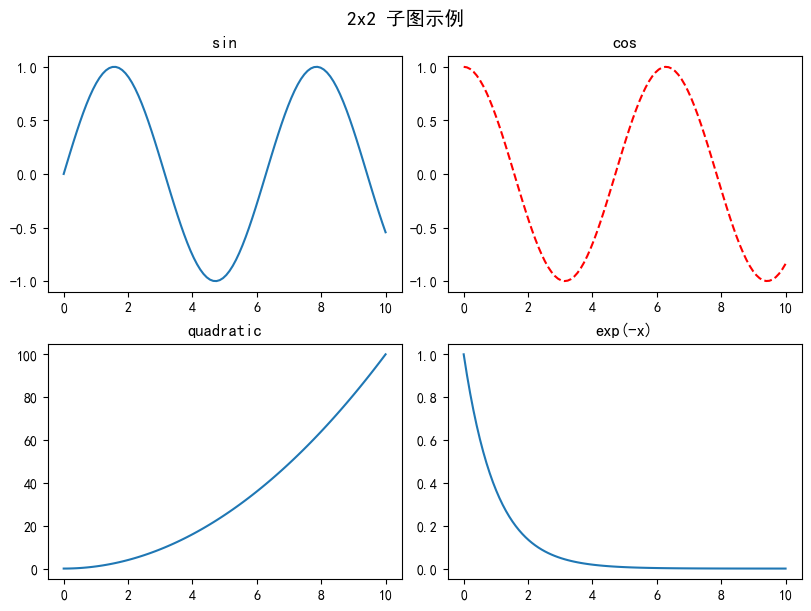

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(8, 6), layout='constrained')
x = np.linspace(0, 10, 100)

axs[0, 0].plot(x, np.sin(x))
axs[0, 0].set_title('sin')

axs[0, 1].plot(x, np.cos(x), 'r--')
axs[0, 1].set_title('cos')

axs[1, 0].plot(x, x**2)
axs[1, 0].set_title('quadratic')

axs[1, 1].plot(x, np.exp(-x))
axs[1, 1].set_title('exp(-x)')

fig.suptitle('2x2 子图示例', fontsize=14)
plt.show()

## 6. 保存图形与中文显示

**保存图形**：`fig.savefig(fname, dpi='figure', bbox_inches='tight', transparent=False)`[citation:7]

| 参数 | 说明 |
|---|---|
| `dpi` | 分辨率，论文常用 300，默认取 Figure 的 dpi |
| `bbox_inches='tight'` | 裁剪空白边距，避免标签被切 |
| `transparent=True` | 透明背景 |
| 格式 | 由扩展名推断：`.png`、`.pdf`、`.svg` |

**中文显示问题**：Matplotlib 默认字体不含中文，会显示为方块。解决方案是在代码开头设置中文字体和负号[citation:8]：
```python
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']  # 按可用性选择
plt.rcParams['axes.unicode_minus'] = False  # 修复负号显示
```

**可用字体**：Windows 常用 `SimHei`（黑体）、`Microsoft YaHei`（微软雅黑）；macOS 可用 `Arial Unicode MS`；Linux 需额外安装中文字体。

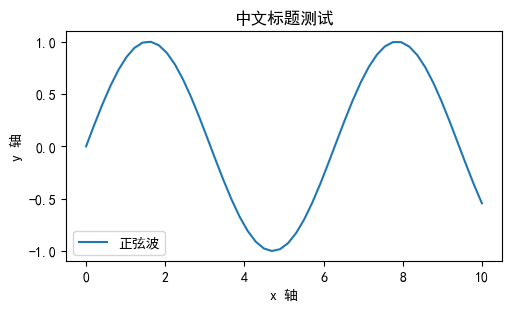

In [9]:
# 中文显示配置（如果字体不可用，中文仍可能显示异常）
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, ax = plt.subplots(figsize=(5, 3), layout='constrained')
x = np.linspace(0, 10, 50)
ax.plot(x, np.sin(x), label='正弦波')
ax.set_xlabel('x 轴')
ax.set_ylabel('y 轴')
ax.set_title('中文标题测试')
ax.legend()

# 保存图形（取消注释以执行）
# fig.savefig('my_plot.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. 综合练习

1. 用 OO 风格绘制 `y = e^{-x} sin(2πx)` 在 `[0, 2]` 区间上的曲线，红色实线，线宽 2，标注坐标轴和标题。
2. 创建 1×2 子图：左边画 100 个标准正态随机数的直方图，右边画它们的散点图（x 为索引，y 为值）。
3. 用 `savefig` 保存练习 2 的图形为 `png`（dpi=200）和 `pdf` 各一份，观察 `bbox_inches='tight'` 的效果。

**参考答案**

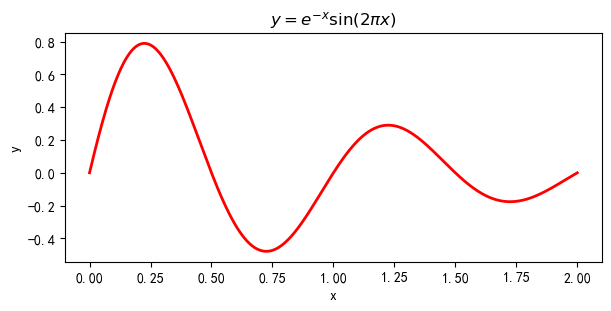

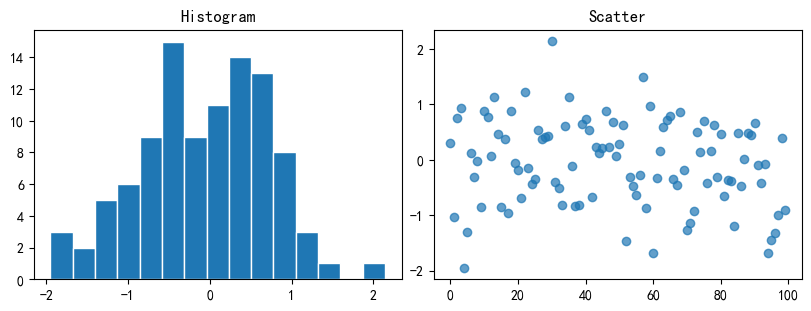

取消 savefig 注释即可保存


In [10]:
# 1. 阻尼正弦曲线
x = np.linspace(0, 2, 500)
y = np.exp(-x) * np.sin(2 * np.pi * x)

fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')
ax.plot(x, y, 'r-', linewidth=2)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title(r'$y = e^{-x}\sin(2\pi x)$')
plt.show()

# 2. 直方图 + 散点图
rng = np.random.default_rng(42)
data = rng.normal(size=100)

fig, axs = plt.subplots(1, 2, figsize=(8, 3), layout='constrained')
axs[0].hist(data, bins=15, edgecolor='white')
axs[0].set_title('Histogram')

axs[1].scatter(range(len(data)), data, alpha=0.7)
axs[1].set_title('Scatter')
plt.show()

# 3. 保存
# fig.savefig('demo.png', dpi=200, bbox_inches='tight')
# fig.savefig('demo.pdf', bbox_inches='tight')
print("取消 savefig 注释即可保存")

## 常见坑点总结

- **`plt.show()` 之前不显示**：Matplotlib 延迟渲染，`plot()` 只是登记，`show()` 才真正绘制。
- **pyplot 与 OO 混用导致混乱**：`plt.plot()` 画到当前 Axes，如果当前 Axes 不是你预期的那个，图会画错地方。复杂场景坚持用 `ax.plot()`。
- **`legend()` 没反应**：绘图时忘了给 `label` 参数，图例为空。
- **中文变方块**：设置 `font.sans-serif` 并关闭 `unicode_minus`，字体名必须系统里确实存在[citation:8]。
- **子图标签被裁**：用 `layout='constrained'` 或 `bbox_inches='tight'` 保存，不要依赖 `tight_layout()`（会关闭 constrained）[citation:15]。
- **`fmt` 与关键字冲突**：`'ro'` 与 `color='g'` 同时写，关键字优先，结果可能不是你想要的。
- **保存的图空白**：在 `show()` 之后 `savefig` 可能得到空白图，先 `savefig` 再 `show`。